In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"] = (8,5)

In [2]:

#Load data
df = pd.read_csv("data/health_study_dataset.csv")

#Some easy check on the data.
df.info()
df.duplicated().sum()
#There is no NaN data in any of the columns, Dtypes seems good for the purpose and there is no duplicates in the CSV-file


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


np.int64(0)

In [3]:
#counting mean, median, min, max for the columns age, weight, height, systolic_pb and cholesterol

desc_stats = df[["age", "weight", "height", "systolic_bp", "cholesterol"]].agg(["mean", "median", "min", "max"])

print(desc_stats)


             age   weight     height  systolic_bp  cholesterol
mean    49.42625   73.413  171.84925   149.178625      4.92915
median  50.00000   73.200  171.35000   149.400000      4.97000
min     18.00000   33.700  144.40000   106.800000      2.50000
max     90.00000  114.400  200.40000   185.900000      7.88000


# Graphs

# Histogram

Visar fördelningen är personernas blodtryck

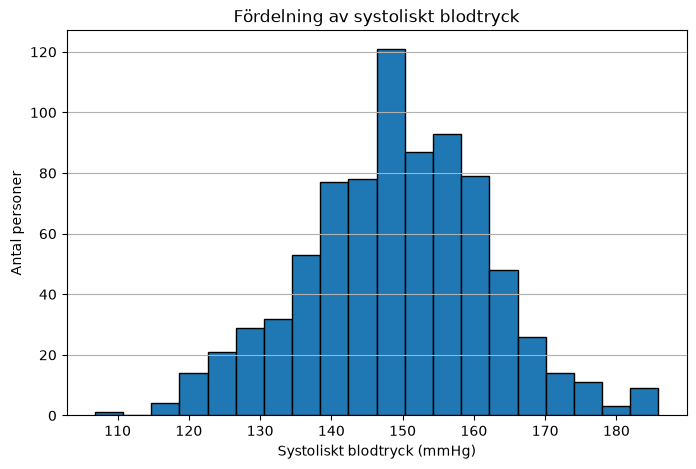

In [4]:
#Histogram for bloodpressure
fig, ax = plt.subplots()
ax.hist(df["systolic_bp"], bins=20, edgecolor="black")
ax.set(title="Fördelning av systoliskt blodtryck", 
       xlabel="Systoliskt blodtryck (mmHg)", 
       ylabel="Antal personer"
       )
ax.grid(True, axis="y")

# Boxplot

Visar vikter på personernas vikter kategoriserade på kön

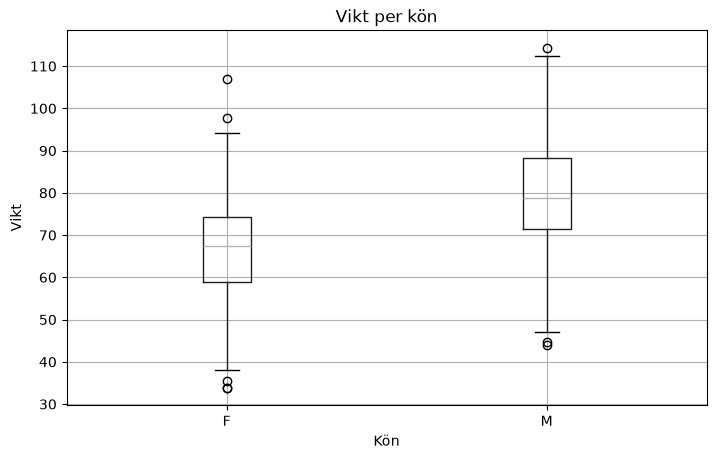

In [5]:
#boxplot for weights categorised by gender
fig, ax = plt.subplots()
df.boxplot(column="weight", by="sex", ax=ax)
ax.set(title="Vikt per kön", 
       xlabel="Kön", 
       ylabel="Vikt"
       )
ax.grid(True)
plt.suptitle("")
plt.show()

# Stapeldiagram

Visar antalet personer som är rökare eller icke-rökare

Text(0.5, 0.98, '')

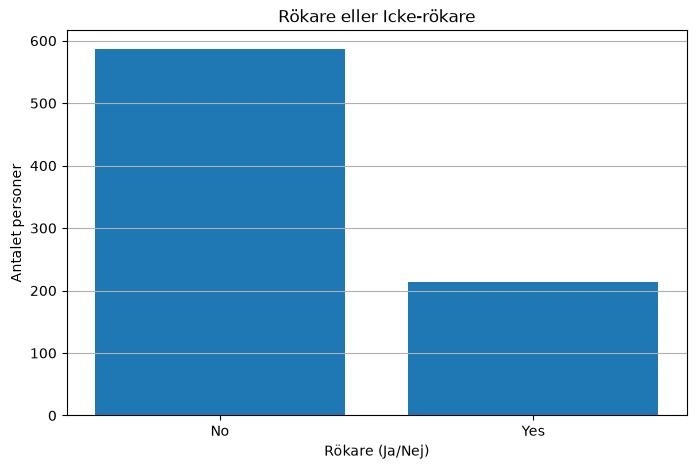

In [6]:
smoker_counts = df["smoker"].value_counts()

fig, ax = plt.subplots()
ax.bar(smoker_counts.index, smoker_counts.values)
ax.set(title="Rökare eller Icke-rökare", 
       xlabel="Rökare (Ja/Nej)", 
       ylabel="Antalet personer"
       )
ax.grid(True, axis="y")
plt.suptitle("")

# Simulation

In [7]:
#Simulation, count share of who has disease

np.random.seed(42)

share_disease = np.mean(df["disease"])


n = 1000
sample = np.random.choice(df["disease"], size=n, replace=True)
share_sample = np.mean(sample)


print(f"Simuleringens andel som har sjukdomen: {share_sample * 100}%. "
      f"Verkliga andelen som har sjukdomen: {share_disease * 100:.2f}%. " 
      f"Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: {(share_sample - share_disease)*100:.2f}%"
    )


Simuleringens andel som har sjukdomen: 6.3%. Verkliga andelen som har sjukdomen: 5.88%. Differensen mellan simuleringen och den verkliga andelen som har sjukdomen: 0.43%


# Konfidensintervall

## Bootstrap

In [8]:
#CI for mean of systolic_bp bootstrap

mean_systolic_bp = np.mean(df["systolic_bp"])

n_boot = 1000
mean_boot = np.empty(n_boot)

for i in range(n_boot):
    boot_sample = np.random.choice(df["systolic_bp"], size=len(df), replace=True)
    mean_boot[i] = np.mean(boot_sample)

boot_low = np.percentile(mean_boot, 2.5)
boot_high = np.percentile(mean_boot, 97.5)

print(f"Bootstrap metoden ger ett 95%igt konfidensintervall mellan {boot_low:.3f} och {boot_high:.3f} ")

Bootstrap metoden ger ett 95%igt konfidensintervall mellan 148.330 och 150.069 


## Normalapproximation


In [9]:
normal_mean_systolic_bp = np.mean(df["systolic_bp"])

n_normal = len(df)
normal_std_systolic_bp = np.std(df["systolic_bp"], ddof=1)
normal_se_systolic_bp = normal_std_systolic_bp / np.sqrt(n_normal)

z = 1.96
half_width = z * normal_se_systolic_bp                              # usually you do std / sqrt(n) but since that is the standarderror, i directly use that variable counting half_width

normal_low = normal_mean_systolic_bp - half_width
normal_high = normal_mean_systolic_bp + half_width

print(f"Normalapproximationsmetoden ger ett 95%igt konfidensintervall mellan {normal_low:.3f} och {normal_high:.3f} ")


Normalapproximationsmetoden ger ett 95%igt konfidensintervall mellan 148.292 och 150.065 


## Jämförelse resultat mellan konfidensintervallen

De är nästan samma vilket stärker tillit till skattningen. Bootstrap: (148.330 och 150.069 ) Normal approximationen: (148.292 och 150.065)

Vi kan anta att med 95% säkerhet ligger det sanna medelvärdet av blodtrycket i spannet som våra konfidensintervall har plockat fram.

## Hypotesprövning

- Utgångsläge (H0 - Nollhypotesen): Det finns ingen skillnad mellan grupperna.
- Anklagelsen (H1 - Alternativhypotesen): Rökare har högre blodtryck än icke-rökare.


In [10]:
smoker = df.loc[df.smoker == "Yes", "systolic_bp"].values
non_smoker = df.loc[df.smoker == "No", "systolic_bp"].values

t_stat_w, p_value_w = stats.ttest_ind(smoker, non_smoker, equal_var=False, alternative="greater")

print(f"Welch t-test: t= {t_stat_w:.3f}, p = {p_value_w:.4f}")

Welch t-test: t= 0.450, p = 0.3264


## Simulering av hypotesprövning

Får fram en vilken Power vi får av effekten vi får av hypotesprövningen

In [11]:
n_smoker = len(smoker)
n_non_smoker = len(non_smoker)

mean_non_smoker = np.mean(non_smoker)
std_non_smoker = np.std(non_smoker)
std_smoker = np.std(smoker)

n_sims = 1000
alpha = 0.05
effect = 0.47

significant_test = 0

for _ in range(n_sims):
    sim_non_smoker = np.random.normal(mean_non_smoker, std_non_smoker, n_non_smoker)
    sim_smoker = np.random.normal(mean_non_smoker + effect, std_smoker, n_smoker)

    _, p_value_w_sim = stats.ttest_ind(sim_smoker, sim_non_smoker, equal_var=False, alternative="greater")

    if p_value_w_sim < alpha:
        significant_test += 1

power = significant_test / n_sims
print(f"Med en effekt på {effect} mmHg, blir power: {power:.3f}")


Med en effekt på 0.47 mmHg, blir power: 0.119


# Vilken Power?

Här plockar vi fram vilken effekt mellan rökare och icke-rökare som skulle krävas för att få mer än 80% Power

In [12]:
for eff in [0.47, 1.0, 1.5, 2.0, 3.0]:
    significant = 0
    for _ in range(n_sims):
        sim_non_smoker = np.random.normal(mean_non_smoker, std_non_smoker, n_non_smoker)
        sim_smoker = np.random.normal(mean_non_smoker + eff, std_smoker, n_smoker)
        _, p = stats.ttest_ind(sim_smoker, sim_non_smoker, equal_var=False, alternative="greater")
        if p < 0.05:
            significant += 1
    print(f"Med en effekt på {eff} mmHg, blir power: {significant/n_sims:.3f}")

Med en effekt på 0.47 mmHg, blir power: 0.105
Med en effekt på 1.0 mmHg, blir power: 0.245
Med en effekt på 1.5 mmHg, blir power: 0.431
Med en effekt på 2.0 mmHg, blir power: 0.593
Med en effekt på 3.0 mmHg, blir power: 0.876


### Resultat och Slutsats (Hypotesprövning)

* **t-värdet:** 0.450
* **p-värdet:** 0.3264

**Tolkning Hypotesprövning:**

Med ett resultat på p-värdet på ca. 33% så innebär detta för oss att om rökning inte hade någon verkligt effekt så skulle vi sen minst lika extrem skillnad eller större i 33% av fallen enbart av slumpen.

Skulle p-värdet vara 0.05 eller lägre finns det en verklig skillnad mellan rökare och icke-rökare. Utfallet på t-testet blev ungefär 0.3264 som är betydligt högre än 0.05 så kan vi därför inte förkasta vår nollhypotes (H0).

Därmed finns det inte tillräckligt med evidens i datan för att hävda att rökare har ett högre blodtryck än icke-rökare.

Det vi ser med vårt t-värde är att rökares medelvärde ser ut att vara högre ut än icke-rökares medelvärde. Detta är inte statistiskt bevisat.

Vi gör även ett vanligt t-test med hjälp av Welch t-testet detta då vi har olika varianser på datan, Welch testet gör antagandet om lika varians https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

# Resultat och slutsats (Power test)

### Resultat
* **Effekten av initiala hypotesprövningen:** 0.47 mmHg
* **Power:** 0.119 (11.9%)

* **Effekten för att nå över 80% power:** 3 mmHg

### Metodval
* **numpy.random.normal** : Genererar simulerade normalfördelade stickprov. https://numpy.org/doc/2.5/reference/random/generated/numpy.random.normal.html
* **scipy.stats.ttest_ind** : Används för att utföra Welch t-test. https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

### Slutord
För att se om vår hypotesprövning är säker så simulerar vi fram 1000 lossasutfall på vår t-test och om det är statistiskt signifikant (p < 0.05) så sparas det. Sedan delar vi det på antalet simuleringar och får då fram 11.9%.

Detta innebär för oss att vid 11.9 % av de 1000 simuleringar som görs har vi ett p-värde under 0.05. Detta är inte en tillräckligt hög statistisk styrka och därmed är vår hypotesprövning inte tillräckligt säker. Detta också i ett samband med att vi har ett p-värde på ca. 33%

Vi såg även över hur stor effekten hade kunnat vara för att nå över 80%, den skulle säkert kunna vara lite lägre, men vi valde att gå på fixed siffror för att testa oss fram. Vi fick då att en effekt på 3 mmHg högre på grupp B skulle ge oss ca. 88% statistisk styrka. Det innebär då att 88% av de 1000 simuleringar som gjorts ges ett p-värde mindre än 0.05.